In [23]:
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.stats import exponnorm, norm
import pandas as pd
import math
from pathlib import Path
import re
import sys

In [24]:
SAVEFILES = True
OVERWRITE = True
SET_JPARAM = False

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
IMT_DATADIR = Path("../../Data/cell_cycle_timing")

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func, fit_EMGMM


In [25]:
file_location = os.path.join(IMT_DATADIR,'SMs*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

['..\\..\\Data\\cell_cycle_timing\\SMs_0.6 kPa DMSO_none.csv',
 '..\\..\\Data\\cell_cycle_timing\\SMs_0.6 kPa erlotinib_none.csv',
 '..\\..\\Data\\cell_cycle_timing\\SMs_4 kPa DMSO_none.csv',
 '..\\..\\Data\\cell_cycle_timing\\SMs_4 kPa erlotinib_none.csv',
 '..\\..\\Data\\cell_cycle_timing\\SMs_55 kPa DMSO_none.csv',
 '..\\..\\Data\\cell_cycle_timing\\SMs_55 kPa erlotinib_none.csv']

In [26]:
SMs = []
for f in filenames:
    tmp_df = pd.read_csv(f, header=None)
    tmp_list = tmp_df[0].tolist()
    SMs.append(tmp_list)


In [27]:
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^IMT.*jparam_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    file_location = os.path.join(IMT_DATADIR,'*IMTs*.csv')
    filepaths = glob.glob(file_location)
    filepaths.sort()
    print(filepaths)

['..\\..\\Data\\cell_cycle_timing\\IMTs_0.6 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\IMTs_0.6 kPa erlotinib_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\IMTs_4 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\IMTs_4 kPa erlotinib_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\IMTs_55 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\IMTs_55 kPa erlotinib_param_orig.csv']


In [28]:
IMTs = []
for f in filepaths:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)


In [29]:
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^G1.*jparam_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    file_location = os.path.join(IMT_DATADIR,'G1s*param_orig.csv')
    filepaths = glob.glob(file_location)
    filepaths.sort()
    print(filepaths)

['..\\..\\Data\\cell_cycle_timing\\G1s_0.6 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\G1s_0.6 kPa erlotinib_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\G1s_4 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\G1s_4 kPa erlotinib_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\G1s_55 kPa DMSO_param_orig.csv', '..\\..\\Data\\cell_cycle_timing\\G1s_55 kPa erlotinib_param_orig.csv']


In [30]:
g1 = []
for f in filepaths:
    tmp_df = pd.read_csv(f,header=None).transpose()
#     tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    g1.append(tmp_df)

In [31]:
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 

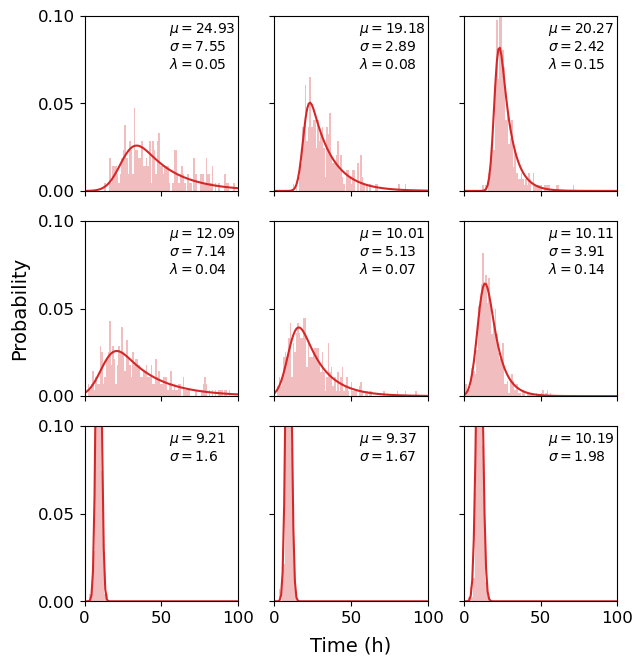

In [32]:
win = 21
pol = 2
size = (7,7)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 100
ymin = 0
ymax = 0.1

fig, axes = plt.subplots(3, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[1])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,0].plot(centers, fitted_curve, color=c2)
axes[0,0].set_xlim([xmin, xmax])
axes[0,0].set_ylim([ymin, ymax])
axes[0,0].set_yticks([0, 0.05, 0.1])
axes[0,0].axes.xaxis.set_ticklabels([])
axes[0,0].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

data = np.array(IMTs[3])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,1].plot(centers, fitted_curve, color=c2)
axes[0,1].set_xlim([xmin, xmax])
axes[0,1].set_ylim([ymin, ymax])
axes[0,1].set_yticks([0, 0.05, 0.1])
axes[0,1].axes.xaxis.set_ticklabels([])
axes[0,1].axes.yaxis.set_ticklabels([])
axes[0,1].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

data = np.array(IMTs[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,2].plot(centers, fitted_curve, color=c2)
axes[0,2].set_xlim([xmin, xmax])
axes[0,2].set_ylim([ymin, ymax])
axes[0,2].set_yticks([0, 0.05, 0.1])
axes[0,2].axes.xaxis.set_ticklabels([])
axes[0,2].axes.yaxis.set_ticklabels([])
axes[0,2].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

G1 = np.array(g1[1])
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,0].plot(centers, fitted_curve, color=c2)
axes[1,0].set_xlim([xmin, xmax])
axes[1,0].set_ylim([ymin, ymax])
axes[1,0].set_yticks([0, 0.05, 0.1])
axes[1,0].axes.xaxis.set_ticklabels([])
axes[1,0].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

G1 = np.array(g1[3])
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,1].plot(centers, fitted_curve, color=c2)
axes[1,1].set_xlim([xmin, xmax])
axes[1,1].set_ylim([ymin, ymax])
axes[1,1].set_yticks([0, 0.05, 0.1])
axes[1,1].axes.xaxis.set_ticklabels([])
axes[1,1].axes.yaxis.set_ticklabels([])
axes[1,1].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

G1 = np.array(g1[5])
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,2].plot(centers, fitted_curve, color=c2)
axes[1,2].set_xlim([xmin, xmax])
axes[1,2].set_ylim([ymin, ymax])
axes[1,2].set_yticks([0, 0.05, 0.1])
axes[1,2].axes.xaxis.set_ticklabels([])
axes[1,2].axes.yaxis.set_ticklabels([])
axes[1,2].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

SM = np.array(SMs[1])
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = norm.fit(data)

fitted_curve = list(norm.pdf(centers, params[0], params[1]))
axes[2,0].plot(centers, fitted_curve, color=c2)
axes[2,0].set_xlim([xmin, xmax])
axes[2,0].set_ylim([ymin, ymax])
axes[2,0].set_yticks([0, 0.05, 0.1])
axes[2,0].text(55, 0.08, f'$\mu = {round(params[0],2)}$\n$\sigma = {round(params[1],2)}$')

SM = np.array(SMs[3])
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = norm.fit(data)

fitted_curve = list(norm.pdf(centers, params[0], params[1]))
axes[2,1].plot(centers, fitted_curve, color=c2)
axes[2,1].set_xlim([xmin, xmax])
axes[2,1].set_ylim([ymin, ymax])
axes[2,1].set_yticks([0, 0.05, 0.1])
axes[2,1].axes.yaxis.set_ticklabels([])
axes[2,1].text(55, 0.08, f'$\mu = {round(params[0],2)}$\n$\sigma = {round(params[1],2)}$')

SM = np.array(SMs[5])
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = norm.fit(data)

fitted_curve = list(norm.pdf(centers, params[0], params[1]))
# fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2,2].plot(centers, fitted_curve, color=c2)
axes[2,2].set_xlim([xmin, xmax])
axes[2,2].set_ylim([ymin, ymax])
axes[2,2].set_yticks([0, 0.05, 0.1])
axes[2,2].axes.yaxis.set_ticklabels([])
axes[2,2].text(55, 0.08, f'$\mu = {round(params[0],2)}$\n$\sigma = {round(params[1],2)}$')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Probability', labelpad=40)

fig1s = Path(SAVEDIR, 'fig3supp.svg')

if SAVEFILES and (OVERWRITE or not fig1s.exists()):
    plt.savefig(fig1s, bbox_inches='tight')
else:
    plt.figure()


C:\Users\olesk\repos\ECM_cell_cycle_model\Figures\Fig3\./../../Python\fits.py:27: RuntimeWarning: overflow encountered in exp
  return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian
C:\Users\olesk\repos\ECM_cell_cycle_model\Figures\Fig3\./../../Python\fits.py:27: RuntimeWarning: invalid value encountered in multiply
  return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian


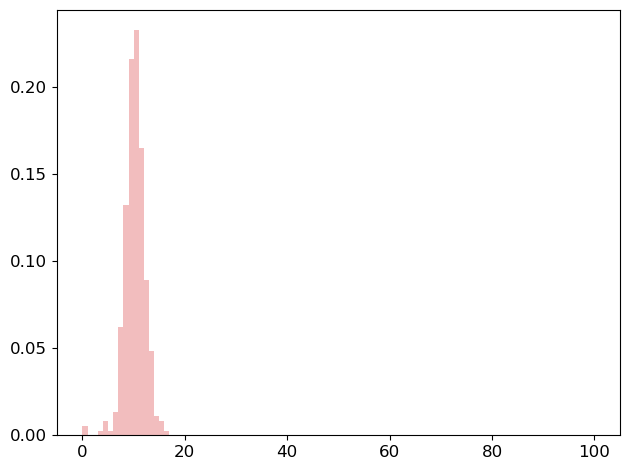

In [33]:
SM = np.array(SMs[5])
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
plt.stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
plt.plot(centers, fitted_curve, color=c2)

In [34]:
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))

In [35]:
popt = [exp_c, params[2], params[1]]
popt

[720.7727009584434, 1.9804918709055432, 10.19002064645483]